#  Integrated Development Environments (IDE) - VS Code, GitHub & company
**Lecturer:** Ana Stojiljkovic, DVM PhD  
Data Science Lab, University of Bern | 2026

---
> **The challenge:** You receive a course notebook, make a change, and want to run it reliably on your computer—then save and share your work without modifying the lecturer’s original repository. What tools do you need?

**In this workshop we will learn:** open a project → run a notebook → save a change with Git → push it to *your* GitHub repository → recreate its Python environment.

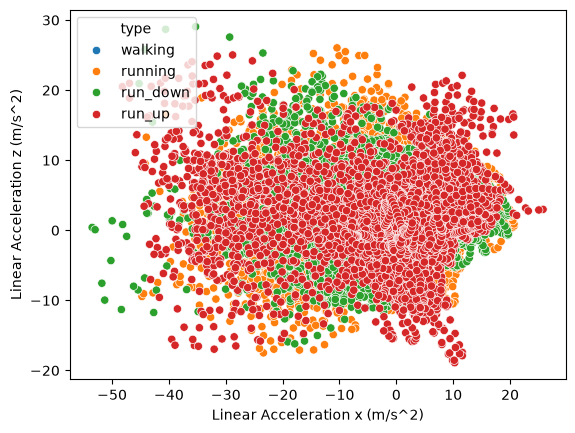

In [ ]:
import seaborn as sns
sns.scatterplot(data=movement, x='Linear Acceleration x (m/s^2)',
                y='Linear Acceleration z (m/s^2)', hue='type');

## Learning outcomes

By the end of this session, you will be able to:

1. Navigate VS Code and identify the Python and Jupyter extensions.
2. Distinguish **Git** (version history on your computer) from **GitHub** (hosting and collaboration).
3. Fork and clone a repository, then review, commit, push and pull a change using VS Code.
4. Explain why a project needs a separate Python environment and select the correct notebook kernel.
5. Explain the roles of `pyproject.toml`, `uv.lock` and `.venv`, and use `uv sync` to set up a course project.

**Success criterion:** You can run a notebook with the correct kernel and see a practice change on *your own* GitHub fork.

---

# Step-by-step installation

- Install **[VS Code](https://code.visualstudio.com/)** and **[Git](https://git-scm.com/downloads)**; create or sign in to your [GitHub account](https://github.com/).
- Install **[uv](https://docs.astral.sh/uv/getting-started/installation/)** and restart your terminal after installation.
- In VS Code, install the Microsoft **Python** and **Jupyter** extensions.
- Verify in a terminal: `git --version` and `uv --version` (the commands should show versions).
- **First check if there is a `pyproject.toml` and `uv.lock` file in the repository:** fork the [DSL course repository](https://github.com/dsl-unibe-ch/machine-learning), clone your fork and run `uv sync` in a terminal. Its complete ML environment may take time to download.

---
# 1 Why an IDE?

A development environment brings together the tools we need to write and run code. It allows us to edit files, execute Python, inspect results, manage dependencies, and track changes.

| Tool | Role in our workflow |
|---|---|
| **VS Code** | The editor/IDE: where we open, edit and inspect the project. |
| **Python** | The interpreter that executes Python code. |
| **Jupyter** | Notebook format and interactive execution inside VS Code. |
| **Git** | Local version control: a history of changes. |
| **GitHub** | Hosts a remote repository and supports sharing/collaboration. |
| **venv / uv** | Isolates and manages the Python packages needed by a project. |

---
# 2 Explore VS Code

### Short tour

Open the **folder**, not just a single `.ipynb` file: `File → Open Folder…` and choose your cloned project.

Find these parts of the interface:

1. **Explorer:** project files, folders, notebooks and `pyproject.toml`.
2. **Editor:** Markdown, Python files and `.ipynb` notebooks.
3. **Integrated terminal:** `Terminal → New Terminal`; use it for `git` and `uv` commands.
4. **Source Control:** the branching icon; shows modified files and commit controls.
5. **Extensions:** install or inspect tools that extend VS Code.
6. **Command Palette:** `View → Command Palette…`; search by action rather than remembering every menu.<br>
*For example Find the command `Python: Select Interpreter`.*<br>
*Tip: Open the Command Palette (⌘ + Shift + P on Mac or Ctrl + Shift + P on Windows), type >Python: Select Interpreter, and select the command.*

**Extensions for this course**

| Install | Why? |
|---|---|
| **Python** (Microsoft) | Python language support and interpreter selection. |
| **Jupyter** (Microsoft) | Open, run and debug `.ipynb` files. |
| *Optional:* GitHub Pull Requests (Microsoft) | Review or create pull requests **later**; not required for commit/push/pull. |

**Important:** Basic Git/GitHub operations are built into VS Code, but **Git itself must be installed**. The Python extension does not install a Python interpreter for you.

---
# 3 Run a notebook with the right Python

An `.ipynb` file contains **Markdown cells** (explanations) and **code cells** (Python). VS Code runs Python code through a selected **kernel**.

1. Open this notebook in VS Code.
2. At the top right, choose **Select Kernel → Python Environments → your project's `.venv`**. If it is not suggested, choose *Select Another Kernel* and locate the project interpreter.
3. Run the next cell with its play button. Run it again after changing the message.
4. Save the notebook; inspect the difference between the code you wrote and its displayed output.

**On macOS/Linux:** the environment's interpreter is usually `.venv/bin/python`.  
**On Windows:** it is usually `.venv\Scripts\python.exe`.

> **Why this matters:** A notebook can display perfectly but fail with `ModuleNotFoundError` if VS Code is using the *wrong* Python environment.

In [ ]:
# Your first notebook cell: change the message and run it.
message = "Hello from the Machine Learning course!"
print(message)

### Which Python is actually running this notebook?

Run the next cell. The path should point into the project’s `.venv` if that kernel is selected.

In [ ]:
import sys
from pathlib import Path

print("Python version:", sys.version.split()[0])
print("Interpreter:", sys.executable)
print("In a .venv folder?", ".venv" in Path(sys.executable).parts)

Is the **terminal's** selected Python automatically the same as the **notebook's** kernel? Not necessarily! You must check both, especially when switching projects.

---
# 4 Git ≠ GitHub

**Git** tracks local versions. **GitHub** hosts a remote copy. You can commit offline; pushing requires a remote and connectivity.

```text
DSL course repository on GitHub
           │ fork (GitHub → your own copy)
           ▼
Your fork on GitHub
           │ clone (download repository + history)
           ▼
Your local folder, opened in VS Code
           │ edit → stage → commit (local history)
           └──────── push ───────────────► Your fork on GitHub
           ◄──────── pull ────────────────┘
```

| Word | Meaning |
|---|---|
| **Fork** | Your own GitHub copy of someone else's repository. |
| **Clone** | Download a repository and its history to your computer. |
| **Stage** | Choose which changes to include in the next commit. |
| **Commit** | Record a snapshot in your **local** Git history. |
| **Push** | Send local commits to a remote repository. |
| **Pull** | Bring remote commits into your current local branch. |

**Ask:** If I click **Commit**, has my colleague already received the change? **No**. 

If I click **Push** to my fork, is the DSL original modified? **No**.

### GitHub sign-in and Git identity

In VS Code, use the **Accounts** menu or follow the GitHub sign-in prompt when cloning/pushing. You do not need a separate GitHub extension for basic operations. A browser may open to authorize VS Code.

Git also needs a name and email for commit authorship. If this has not been configured, set it in the **terminal** (use your own details):

```bash
# Optional if Git already knows your identity
 git config --global user.name "Your Name"
 git config --global user.email "your-email-or-github-noreply-address"
```

If you prefer, use your GitHub-provided `noreply` email to avoid exposing a personal address in public commits. Do not paste tokens or passwords into notebooks or commit them to Git.


### Keeping Files Out of Git: `.gitignore`

Not every file in your project needs to be shared on GitHub. For example, you may want to exclude **large datasets, temporary files, local environments, or files containing sensitive information**.

Add their names or patterns to a file called `.gitignore` in your repository:

```gitignore
.venv/
.env
data/
__pycache__/
```

Git will ignore matching files that have not already been tracked.

**Important:** Never commit passwords, API keys, or other secrets. If a sensitive file has already been committed, adding it to `.gitignore` will not remove it from Git’s history.

---
# 5 Guided Git exercise: from fork to push

**We will modify our own forks—not the shared DSL repository.**

**A. Fork (GitHub website)**

1. Open the DSL repository and click **Fork**.
2. Choose **your GitHub account** as the owner.
3. Open your resulting repository, `https://github.com/YOUR-USERNAME/machine-learning`.

**B. Clone (VS Code)**

4. Copy the URL of **your fork** (not the DSL original).
5. In the Command Palette run **Git: Clone**, paste the URL, choose a local folder, and open it.
6. If prompted to trust this folder, confirm only after verifying it is your own course fork.

**C. Edit, review, commit and push (VS Code)**

7. In the Explorer, create `my-workshop-notes.md` with one line: `My first VS Code practice change.`
8. Open **Source Control**. Inspect the new file and the difference; stage **only** your notes file using `+`.
9. Write the commit message `Add my workshop notes` and click **Commit**.
10. Choose **Push** in Source Control (or **Sync Changes** if appropriate). Open *your fork* on GitHub and confirm the file appears.

**Check:** `git status` in the terminal should report a clean working tree if no other files were changed. Avoid staging `.venv/`, downloaded data, credentials or unrelated notebook outputs.

### The same ideas in the terminal

You can do the same operations using the command line. The VS Code buttons operate on Git's underlying state.

```bash
git status
git add my-workshop-notes.md
git commit -m "Add my workshop notes"
git push
```

**What about the repository authors's updates?** <br>
Your `origin` normally points to *your fork*. Pulling from `origin` gets updates from your fork, **not automatically** from the DSL repository. On GitHub, use **Sync fork** to bring in later upstream changes when you choose to; then pull those updates locally. We won't merge upstream changes during this introductory exercise.

### Note Cornel
Organise Commits as "working steps" (if I wanted to change a red button, I call it like that)

---
# 6 Pull: receive a change

**Work in your own GitHub fork.** The aim is to see a remote change arrive locally.

1. First, make sure your local changes are committed and pushed.
2. On **your fork's GitHub website**, open `my-workshop-notes.md`, click Edit, add `Edited on GitHub`, then commit the change there.
3. Return to VS Code. In Source Control choose **Pull** (in the `…` menu), or use `git pull` in the terminal.
4. Reopen `my-workshop-notes.md`. Can you find the new line?

**Think–pair–share:** What would happen if you and a colleague both edit the *same line* differently? Git may ask you to resolve a **merge conflict**. We will not practise conflict resolution today, but it is normal—not a sign that Git is broken.

---
# 7 Why virtual environments?

Imagine Project A requires an older version of a library, while Project B uses a newer one. Installing everything into one shared Python installation can make one project break when you update the other.

A **virtual environment** gives a project its own Python executable and installed packages:

```text
Your computer
├── Project A / .venv  → packages for A
└── Project B / .venv  → packages for B
```

[It isolates Python dependencies](https://carpentries-incubator.github.io/better-research-software/03-reproducible-dev-environment.html); it does **not** create an entirely separate operating system. Reproducibility also depends on recording the versions and ensuring they are available for each operating system

<img src="figures/virtual-env.png">

### The traditional approach: Python `venv` + `pip`

These examples are for **comparison**. Do not run them inside our already configured course repository:

| Step | macOS / Linux terminal | Windows terminal |
|---|---|---|
| Create an environment | `python3 -m venv .venv` | `py -m venv .venv` |
| Install a package into it | `.venv/bin/python -m pip install ipykernel` | `.venv\Scripts\python.exe -m pip install ipykernel` |

Using the environment's Python path avoids needing an activation command for this demonstration. `pip` installs packages, but it does **not** automatically record direct dependencies in a project file and lock all transitive dependencies. That extra bookkeeping is where **uv's project** workflow helps.

---
# 8 uv: a manageable project environment

`uv` can manage Python versions, dependency declarations, a lockfile and the project's virtual environment.

**The three key files/directories:**

```text
machine-learning/
├── pyproject.toml   ← Which dependencies does the course require?
├── uv.lock          ← Which exact compatible versions were resolved?
├── .python-version  ← Which Python version should uv use? (if provided)
└── .venv/           ← Installed local environment; do NOT commit
```

**Why initialize?** For a brand-new project, `uv init --bare` creates a minimal `pyproject.toml`. **Do not run it again** if the course already contains that file. The project's notebook folder does not need to be an installable Python package; `[tool.uv] package = false` is a valid optional explicit choice.

**For an existing course repo (terminal in its root):**

```bash
uv sync                  # Create/update .venv from project configuration
uv run python --version  # Run using the project environment
```

**If YOU are maintaining a project and decide it needs a new package:**

```bash
uv add <package-name>     # Updates pyproject.toml, uv.lock and .venv
uv remove <package-name>  # Removes a declared dependency
```

**Do not run `uv add` just to complete the workshop**; try it later in your own fork or a disposable project. It changes project files. `uv sync` can remove packages installed manually but absent from the lockfile. Avoid mixing `%pip install` with your course's uv-managed environment.

**Key distinction:** `uv sync` reproduces the recorded environment; it does **not** automatically upgrade every library to its newest release.

### Practice: verify the environment you're using

In the **VS Code terminal**, from the project root, run `uv sync` if needed, then confirm the Python version with `uv run python --version`. In this notebook, select the project's `.venv` kernel and run the next cell.

Your paths may be different on macOS and Windows. That's expected. Check that the path belongs to **this project**.

In [1]:
# This cell uses only Python's standard library.
import sys
from importlib import metadata

print("Notebook interpreter:", sys.executable)
for name in ("ipykernel", "numpy", "scikit-learn"):
    try:
        print(f"{name}: {metadata.version(name)}")
    except metadata.PackageNotFoundError:
        print(f"{name}: not installed in this kernel")

Notebook interpreter: c:\Users\guebeli.SPW\AppData\Local\miniforge3\envs\CASADS\python.exe
ipykernel: 7.3.0
numpy: 2.5.3
scikit-learn: 1.9.1


### Three concepts to remember

| If you want to… | Do this |
|---|---|
| Start from an **existing** course repository | Clone your fork → `uv sync` → select `.venv` as notebook kernel. |
| Add a new dependency **as a project maintainer** | `uv add package-name` → test → commit `pyproject.toml` and `uv.lock`. |
| Share the environment | Commit `pyproject.toml`, `uv.lock` and any `.python-version`; **never** commit `.venv/`. |

**Check `.gitignore`:** It should include `.venv/`. A virtual environment is machine-specific and potentially very large.

---
# 9 Quiz to check your understanding

1. Why can **Commit** succeed even if you are offline?
2. If you push to your own fork, does that change the DSL repository?
3. Which VS Code control would you use if a notebook says `ModuleNotFoundError` even though a package appears installed?
4. Which file records **direct project dependencies**, and which records **resolved versions**?
5. What single command should you run after pulling course changes that alter the environment?

**Answers to check:** local Git history; no; select the correct kernel/interpreter; `pyproject.toml` and `uv.lock`; `uv sync`.

**Take-home challenge (optional):** Create a tiny new project in a separate folder with `uv init --bare`, add one lightweight dependency, and explain which files changed. Keep this separate from the course repository.


# 10 Getting Started with UBELIX

[**UBELIX**](https://hpc-unibe-ch.github.io/) is the high-performance computing (HPC) infrastructure at the University of Bern. In this workshop, we will use it to run VS Code on dedicated computing resources.

You will need your **UniBE account**, which you received when enrolling in this course.

**Step 1: Use VPN to connect to the university network**  
Install [FortiClient](https://serviceportal.unibe.ch/esc?id=kb_article_view&sysparm_article=KB0010032) for your operating system and follow the instructions to set up the VPN connection.

**Step 2: Access the UBELIX Dashboard**  
Open the [UBELIX Dashboard](https://ondemand.hpc.unibe.ch/pun/sys/dashboard) and complete the registration if this is your first time using it.

**Step 3: Upload your data**  
In the "Files/Home Directory" you can create new folders, upload your data and download them back to your local computer (up to 1TB storage space).


**Step 4: Start an interactive VS Code session**  
Reserve computing resources through the dashboard and launch a VS Code session.
- Go to "My Interactive Sessions"
- Select VSCode
- Select the "gratis" account
- QoS "jog_gratis" or "job_cpu_preemptable"/"job_gpu_preemptable" (see the difference [here](https://hpc-unibe-ch.github.io/changelog-20251201/#freetier-resources))
- Select the needed instance size
- Select the time you need the interactive session for
- Launch the interactive job
- When the sesssion is running (green) you can use the "connect to VSCode" to open your interactive session in the browser



### Official documentation

- [VS Code: Python](https://code.visualstudio.com/docs/languages/python) · [VS Code: Jupyter notebooks](https://code.visualstudio.com/docs/datascience/jupyter-notebooks) · [VS Code: GitHub](https://code.visualstudio.com/docs/sourcecontrol/github)
- [GitHub: Git basics](https://docs.github.com/en/get-started/using-git/about-git) · [Working with forks](https://docs.github.com/en/pull-requests/how-tos/work-with-forks)
- [uv: projects](https://docs.astral.sh/uv/guides/projects/) · [uv: Jupyter in VS Code](https://docs.astral.sh/uv/guides/integration/jupyter/) · [uv: installation](https://docs.astral.sh/uv/getting-started/installation/)